1. Dataset Requirements & Deadlines
Source: Choose dataset from Kaggle.

Size: It should have at least 2,000 rows. (Under special circumstances, I may approve datasets less than 2,000 rows, but the absolute minimum is 1,000 rows).

Timeline: Start looking for a dataset TODAY (it takes 2 weeks to finalize the dataset and get my approval).

Deadline: Present your dataset for approval by me before October 12, 2026.

⚠️ Warning: If your dataset is not approved by me, your project submission will NOT be graded.

2. Pre-Processing & Cleanup Requirements
Once approved, perform a cleanup on the dataset using the guidelines you learned in Modules 4 and 5.

Some of the pre-processing exercises to be performed on the dataset are:

Filling NaN and Null values with appropriate values

Scaling: Changing the range of your data

Normalization: Adjusting the shape of your data's distribution

Class Balancing the dataset

One-hot encoding

Encoding: Converting categorical data to numbers

Feature engineering

🚨 CRITICAL RULE: NEVER EVER change the dataset manually. If you do this, you have failed the exam. All changes must be done via Python code in Jupyter Lab.

3. Notebook & Visualization Requirements
Matplotlib: Use Matplotlib to plot the data distributions in the code and show how the data before and after preprocessing looks like (e.g., balancing the dataset).

Sample Data: Print sample data as it gets processed in the code.

Jupyter Notebook: Build a Jupyter notebook to show the dataset before and after cleanup.

ML Problem Discussion: Discuss how you would use this dataset to solve an ML problem.

In [1]:
# pip install matplotlib numpy pandas seaborn scikit-learn
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    precision_score,
    recall_score,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder

ModuleNotFoundError: No module named 'matplotlib'

In [ ]:
DATA_URL = "/content/healthcare_dataset.csv"
df = pd.read_csv(DATA_URL)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0], "| Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 55500 | Columns: 15


In [ ]:
# Split before analysis or preprocessing
train_df, test_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["Test Results"]
)

train_df = train_df.copy()
test_df = test_df.copy()

print("Original dataset:", df.shape)
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)
print("\nFirst five training rows:")
display(train_df.head())

Original dataset: (55500, 15)
Training dataset: (38850, 15)
Testing dataset: (16650, 15)

First five training rows:


,Name,Age,Gender,Blood Type,Medical Condition,Date of Admission,Doctor,Hospital,Insurance Provider,Billing Amount,Room Number,Admission Type,Discharge Date,Medication,Test Results
39555,StANleY MOrRISON,20,Female,B+,Obesity,2019-07-31,Brittney Simpson,PLC Cruz,Blue Cross,21189.286364,276,Elective,2019-08-04,Ibuprofen,Normal
25382,TrAVis smith,40,Female,B+,Arthritis,2021-05-02,Alison Powell,Richards-Mason,Cigna,7019.697644,407,Urgent,2021-05-08,Penicillin,Normal
41604,MicHAEL siMs,20,Female,O+,Obesity,2019-07-14,Angela Hodges,"Flynn, Hart Hodges and",Cigna,37688.012482,299,Urgent,2019-08-06,Aspirin,Normal
51069,aNDREw hILl,81,Male,A-,Obesity,2021-04-29,Hannah Cochran,Greene-Fritz,Medicare,39471.282888,438,Urgent,2021-05-11,Ibuprofen,Inconclusive
45759,JoHN graNt,52,Male,AB-,Arthritis,2020-04-13,John Lucero,"Moreno Jones Little, and",Aetna,19113.505036,379,Elective,2020-04-25,Aspirin,Inconclusive


In [ ]:
# Explore only the training dataset
print("\nData types and non-null counts:")
train_df.info()

print("\nDescriptive statistics:")
display(train_df.describe(include="all").transpose())

print("\nMissing values by column:")
print(train_df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate rows:")
print(train_df.duplicated().sum())

print("\nUnique values in categorical columns:")
categorical_columns = [
    "Test Results",
    "Medication",
    "Medical Condition",
    "Blood Type",
    "Gender",
    "Admission Type"
]

for column in categorical_columns:
    print(f"{column}: {train_df[column].dropna().unique().tolist()}")

print("\nTest Result Counts:")
print(train_df["Test Results"].value_counts())

print("\nTest Result Percentages:")
print(
    train_df["Test Results"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2))


Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
Index: 38850 entries, 39555 to 23462
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Name                38850 non-null  object 
 1   Age                 38850 non-null  int64  
 2   Gender              38850 non-null  object 
 3   Blood Type          38850 non-null  object 
 4   Medical Condition   38850 non-null  object 
 5   Date of Admission   38850 non-null  object 
 6   Doctor              38850 non-null  object 
 7   Hospital            38850 non-null  object 
 8   Insurance Provider  38850 non-null  object 
 9   Billing Amount      38850 non-null  float64
 10  Room Number         38850 non-null  int64  
 11  Admission Type      38850 non-null  object 
 12  Discharge Date      38850 non-null  object 
 13  Medication          38850 non-null  object 
 14  Test Results        38850 non-null  object 
dtypes: float64(1), int64(

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Name,38850,36154,jAmes nASH,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,38850.0,NaN,NaN,NaN,51.566409,19.622188,13.0,35.0,52.0,69.0,89.0
Gender,38850,2,Female,19482,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Blood Type,38850,8,A+,4941,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medical Condition,38850,6,Diabetes,6510,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Date of Admission,38850,1827,2022-07-01,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Doctor,38850,30408,Robert Smith,18,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Hospital,38850,29796,LLC Smith,30,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Insurance Provider,38850,5,Cigna,7912,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Billing Amount,38850.0,NaN,NaN,NaN,25544.497362,14227.425852,-2008.49214,13256.287035,25533.854702,37870.269121,52764.276736



Missing values by column:
Name                  0
Age                   0
Gender                0
Blood Type            0
Medical Condition     0
Date of Admission     0
Doctor                0
Hospital              0
Insurance Provider    0
Billing Amount        0
Room Number           0
Admission Type        0
Discharge Date        0
Medication            0
Test Results          0
dtype: int64

Duplicate rows:
251

Unique values in categorical columns:
Test Results: ['Normal', 'Inconclusive', 'Abnormal']
Medication: ['Ibuprofen', 'Penicillin', 'Aspirin', 'Lipitor', 'Paracetamol']
Medical Condition: ['Obesity', 'Arthritis', 'Cancer', 'Diabetes', 'Asthma', 'Hypertension']
Blood Type: ['B+', 'O+', 'A-', 'AB-', 'B-', 'AB+', 'A+', 'O-']
Gender: ['Female', 'Male']
Admission Type: ['Elective', 'Urgent', 'Emergency']

Test Result Counts:
Test Results
Abnormal        13039
Normal          12962
Inconclusive    12849
Name: count, dtype: int64

Test Result Percentages:
Test Results
Abnormal   

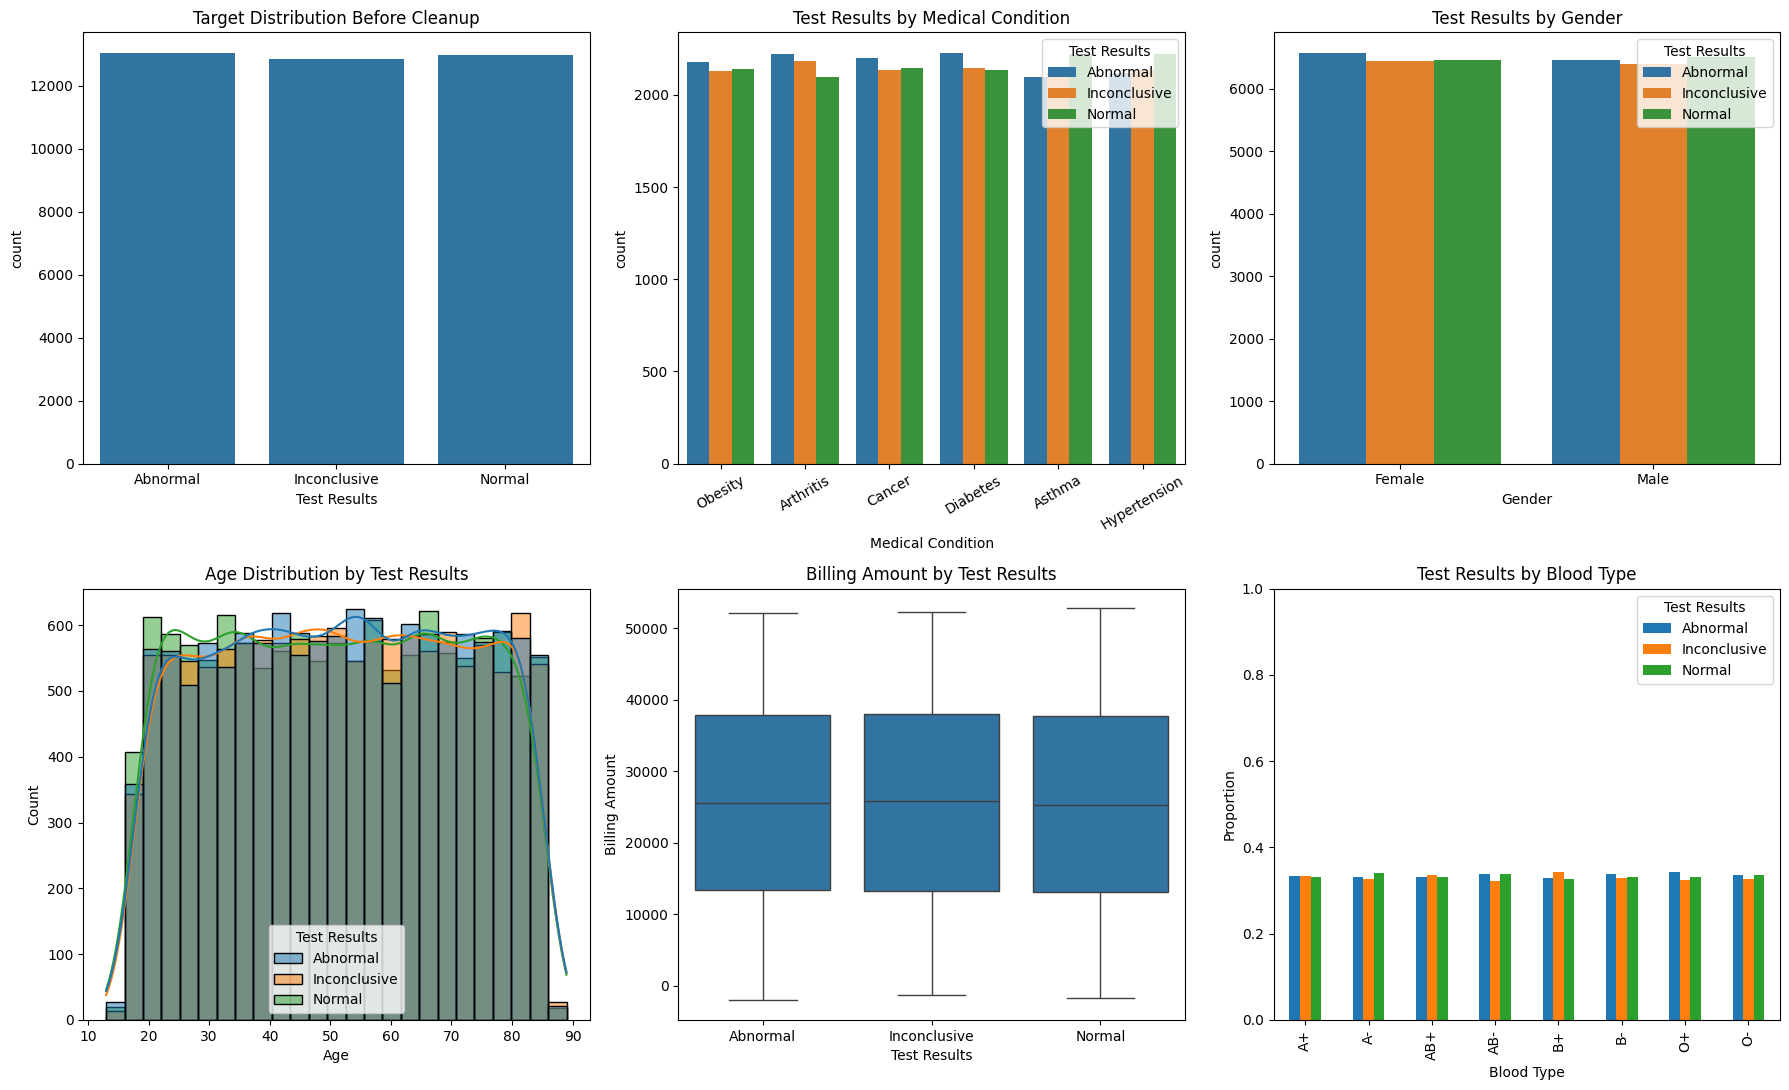


Test Results by Gender (Proportions):


Test Results,Abnormal,Inconclusive,Normal
Gender,,,
Female,0.3376,0.3310,0.3314
Male,0.3336,0.3304,0.3359



Test Results by Medical Condition (Proportions):


Test Results,Abnormal,Inconclusive,Normal
Medical Condition,,,
Arthritis,0.3415,0.3361,0.3224
Asthma,0.3254,0.3295,0.3451
Cancer,0.3396,0.3293,0.3311
Diabetes,0.3422,0.3295,0.3283
Hypertension,0.3269,0.3300,0.3430
Obesity,0.3379,0.3300,0.3320


In [ ]:
# Visualize training data before cleanup
result_order = ["Abnormal", "Inconclusive", "Normal"]

fig, axes = plt.subplots(2, 3, figsize=(18, 11))

sns.countplot(
    data=train_df, x="Test Results",
    order=result_order, ax=axes[0, 0]
)
axes[0, 0].set_title("Target Distribution Before Cleanup")

sns.countplot(
    data=train_df, x="Medical Condition",
    hue="Test Results", hue_order=result_order,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Test Results by Medical Condition")
axes[0, 1].tick_params(axis="x", rotation=30)

sns.countplot(
    data=train_df, x="Gender",
    hue="Test Results", hue_order=result_order,
    ax=axes[0, 2]
)
axes[0, 2].set_title("Test Results by Gender")

sns.histplot(
    data=train_df, x="Age",
    hue="Test Results", hue_order=result_order,
    bins=25, kde=True, ax=axes[1, 0]
)
axes[1, 0].set_title("Age Distribution by Test Results")

sns.boxplot(
    data=train_df, x="Test Results", y="Billing Amount",
    order=result_order, ax=axes[1, 1]
)
axes[1, 1].set_title("Billing Amount by Test Results")

result_by_blood_type = pd.crosstab(
    train_df["Blood Type"],
    train_df["Test Results"],
    normalize="index"
).reindex(columns=result_order, fill_value=0)

result_by_blood_type.plot(
    kind="bar",
    ax=axes[1, 2]
)
axes[1, 2].set_title("Test Results by Blood Type")
axes[1, 2].set_xlabel("Blood Type")
axes[1, 2].set_ylabel("Proportion")
axes[1, 2].set_ylim(0, 1)
axes[1, 2].legend(title="Test Results")

fig.tight_layout()
plt.show()

print("\nTest Results by Gender (Proportions):")
test_results_by_gender = pd.crosstab(
    train_df["Gender"],
    train_df["Test Results"],
    normalize="index"
).reindex(columns=result_order, fill_value=0)

display(test_results_by_gender.round(4))

print("\nTest Results by Medical Condition (Proportions):")
test_results_by_condition = pd.crosstab(
    train_df["Medical Condition"],
    train_df["Test Results"],
    normalize="index"
).reindex(columns=result_order, fill_value=0)

display(test_results_by_condition.round(4))

In [ ]:
# Remove duplicates from training data only
rows_before = len(train_df)
train_df = train_df.drop_duplicates().copy()

print("Rows before cleanup:", rows_before)
print("Duplicates removed:", rows_before - len(train_df))
print("Rows after cleanup:", len(train_df))
print("Remaining duplicates:", train_df.duplicated().sum())

# Inspect negative billing amounts before deciding how to handle them
negative_billing = train_df["Billing Amount"] < 0

print("\nNegative billing amounts:", negative_billing.sum())

display(
    train_df.loc[
        negative_billing,
        ["Age", "Billing Amount", "Test Results"]
    ].head(10)
)

Rows before cleanup: 38850
Duplicates removed: 251
Rows after cleanup: 38599
Remaining duplicates: 0

Negative billing amounts: 78


,Age,Billing Amount,Test Results
50099,43,-1316.618581,Inconclusive
5708,23,-353.865186,Inconclusive
45423,85,-1129.997176,Normal
54136,64,-199.663795,Abnormal
25868,49,-124.649036,Normal
2696,74,-135.986000,Abnormal
29484,39,-1316.618581,Inconclusive
53204,55,-306.364925,Normal
28260,71,-599.265359,Abnormal
6961,83,-43.098522,Abnormal


In [ ]:
# Project assumption: billing amounts must be non-negative
billing_before = train_df["Billing Amount"].copy()
negative_mask = billing_before < 0

# Mark negative amounts as missing
train_df.loc[negative_mask, "Billing Amount"] = np.nan

# Learn the replacement value from training data only
billing_imputer = SimpleImputer(strategy="median")

train_df["Billing Amount"] = billing_imputer.fit_transform(
    train_df[["Billing Amount"]]
).ravel()

print("Negative amounts replaced:", negative_mask.sum())
print("Training median used:", round(billing_imputer.statistics_[0], 2))
print("Remaining negative amounts:",
      (train_df["Billing Amount"] < 0).sum())
print("Remaining missing amounts:",
      train_df["Billing Amount"].isna().sum())

print("\nSample corrected values:")
display(pd.DataFrame({
    "Before": billing_before.loc[negative_mask],
    "After": train_df.loc[negative_mask, "Billing Amount"]
}).head(10))

Negative amounts replaced: 78
Training median used: 25572.76
Remaining negative amounts: 0
Remaining missing amounts: 0

Sample corrected values:


,Before,After
50099,-1316.618581,25572.759954
5708,-353.865186,25572.759954
45423,-1129.997176,25572.759954
54136,-199.663795,25572.759954
25868,-124.649036,25572.759954
2696,-135.986000,25572.759954
29484,-1316.618581,25572.759954
53204,-306.364925,25572.759954
28260,-599.265359,25572.759954
6961,-43.098522,25572.759954


,Before,After
39555,21189.286364,1912.201259
25382,7019.697644,856.223096
41604,37688.012482,2906.241415
51069,39471.282888,3005.560998
45759,19113.505036,1774.105412


Skewness before: 0.0006
Skewness after: -0.2478


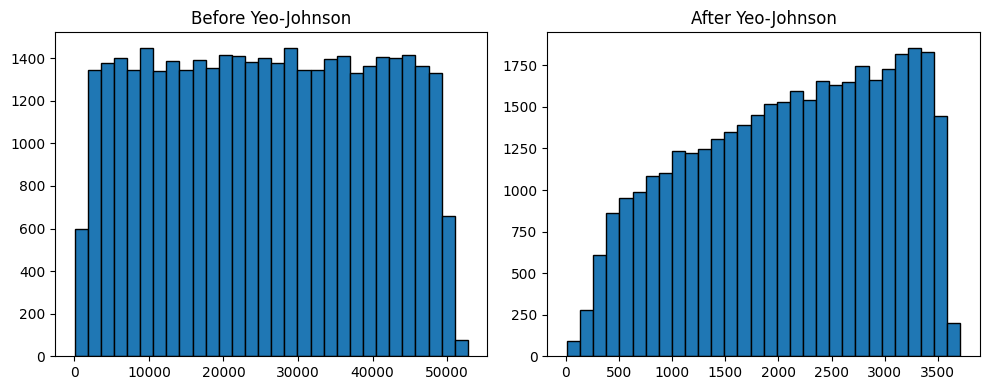

In [ ]:
from sklearn.preprocessing import PowerTransformer

before = train_df["Billing Amount"].copy()

billing_transformer = PowerTransformer(
    method="yeo-johnson", standardize=False
)
train_df["Billing Amount"] = billing_transformer.fit_transform(
    train_df[["Billing Amount"]]
).ravel()

display(pd.DataFrame({
    "Before": before,
    "After": train_df["Billing Amount"]
}).head())

print("Skewness before:", round(before.skew(), 4))
print("Skewness after:", round(train_df["Billing Amount"].skew(), 4))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].hist(before, bins=30, edgecolor="black")
axes[0].set_title("Before Yeo-Johnson")
axes[1].hist(train_df["Billing Amount"], bins=30, edgecolor="black")
axes[1].set_title("After Yeo-Johnson")
plt.tight_layout()
plt.show()
train_df["Billing Amount"] = before.copy()

### Distribution Transformation

A Yeo-Johnson transformation was applied to Billing Amount using
training data only. Skewness changed from 0.0006 to -0.2478,
introducing slight negative skewness into an already nearly
symmetric distribution.

The corrected billing values were restored before scaling because
the transformation did not improve symmetry. Near-zero skewness
alone does not indicate a normal distribution.

,Count,Percentage
Test Results,,
Abnormal,12950,33.55
Normal,12868,33.34
Inconclusive,12781,33.11


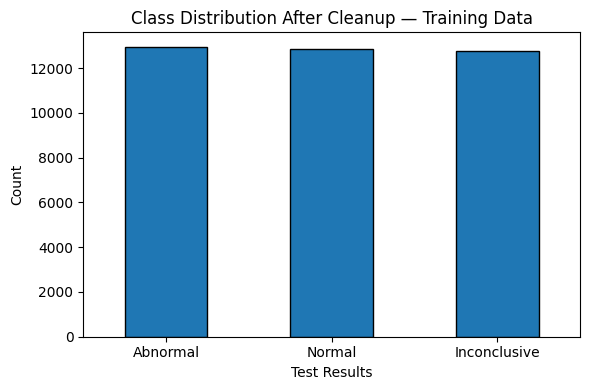

In [ ]:
counts = train_df["Test Results"].value_counts()

display(pd.DataFrame({
    "Count": counts,
    "Percentage": (counts / counts.sum() * 100).round(2)
}))

counts.plot(kind="bar", figsize=(6, 4), edgecolor="black")
plt.title("Class Distribution After Cleanup — Training Data")
plt.ylabel("Count")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

### Class Balance

After cleanup, the training dataset contains 12,950 Abnormal results
(33.55%), 12,868 Normal results (33.34%), and 12,781 Inconclusive
results (33.11%).

The classes are approximately balanced. Therefore, oversampling
and undersampling are unnecessary, and the existing class
distribution is retained. The testing dataset remains untouched.

In [ ]:
# Feature engineering: create age groups
train_df["Age_Group"] = pd.cut(
    train_df["Age"],
    bins=[-np.inf, 17, 39, 59, np.inf],
    labels=["Under 18", "18-39", "40-59", "60+"]
)

print("Feature engineering sample:")
display(train_df[["Age", "Age_Group"]].head(10))

# Encode the target separately
label_encoder = LabelEncoder()
y_train = label_encoder.fit_transform(train_df["Test Results"])

print("\nTarget encoding:")
for number, label in enumerate(label_encoder.classes_):
    print(f"{label} = {number}")

# Select input features
columns_to_drop = [
    "Test Results",
    "Name",
    "Date of Admission",
    "Doctor",
    "Hospital",
    "Insurance Provider",
    "Room Number",
    "Discharge Date"
]
X_train = train_df.drop(columns=columns_to_drop).copy()

# One-hot encode categorical features
df_encoded = pd.get_dummies(
    X_train,
    columns=[
        "Medication",
        "Medical Condition",
        "Blood Type",
        "Gender",
        "Admission Type",
        "Age_Group"
    ],
    dtype=int
)

print("\nEncoded training features:")
display(df_encoded.head())
print("Encoded features shape:", df_encoded.shape)
print("Target shape:", y_train.shape)

Feature engineering sample:


,Age,Age_Group
39555,20,18-39
25382,40,40-59
41604,20,18-39
51069,81,60+
45759,52,40-59
41213,56,40-59
27832,30,18-39
41978,32,18-39
48054,33,18-39
23438,67,60+



Target encoding:
Abnormal = 0
Inconclusive = 1
Normal = 2

Encoded training features:


,Age,Billing Amount,Medication_Aspirin,Medication_Ibuprofen,Medication_Lipitor,Medication_Paracetamol,Medication_Penicillin,Medical Condition_Arthritis,Medical Condition_Asthma,Medical Condition_Cancer,...,Blood Type_O-,Gender_Female,Gender_Male,Admission Type_Elective,Admission Type_Emergency,Admission Type_Urgent,Age_Group_Under 18,Age_Group_18-39,Age_Group_40-59,Age_Group_60+
39555,20,21189.286364,0,1,0,0,0,0,0,0,...,0,1,0,1,0,0,0,1,0,0
25382,40,7019.697644,0,0,0,0,1,1,0,0,...,0,1,0,0,0,1,0,0,1,0
41604,20,37688.012482,1,0,0,0,0,0,0,0,...,0,1,0,0,0,1,0,1,0,0
51069,81,39471.282888,0,1,0,0,0,0,0,0,...,0,0,1,0,0,1,0,0,0,1
45759,52,19113.505036,1,0,0,0,0,1,0,0,...,0,0,1,1,0,0,0,0,1,0


Encoded features shape: (38599, 30)
Target shape: (38599,)


### Feature Engineering and Encoding

Age_Group was created from Age using four predefined groups:
under 18, 18–39, 40–59, and 60+. Grouping ages provides an additional
representation that may help capture differences between age ranges.
The original Age variable is retained to preserve numerical detail.

Categorical input features, including Age_Group, were one-hot encoded.
Test Results was encoded separately as Abnormal = 0, Inconclusive = 1,
and Normal = 2. The target is excluded from the input features.

Before scaling:


,Age,Billing Amount
39555,20,21189.286364
25382,40,7019.697644
41604,20,37688.012482
51069,81,39471.282888
45759,52,19113.505036



After scaling:


,Age,Billing Amount
39555,-1.608636,-0.311072
25382,-0.589303,-1.310541
41604,-1.608636,0.852685
51069,1.500329,0.978471
45759,0.022296,-0.457490



Scaled feature statistics:


,Age,Billing Amount
mean,3.828931e-17,1.325399e-16
std,1.000013e+00,1.000013e+00


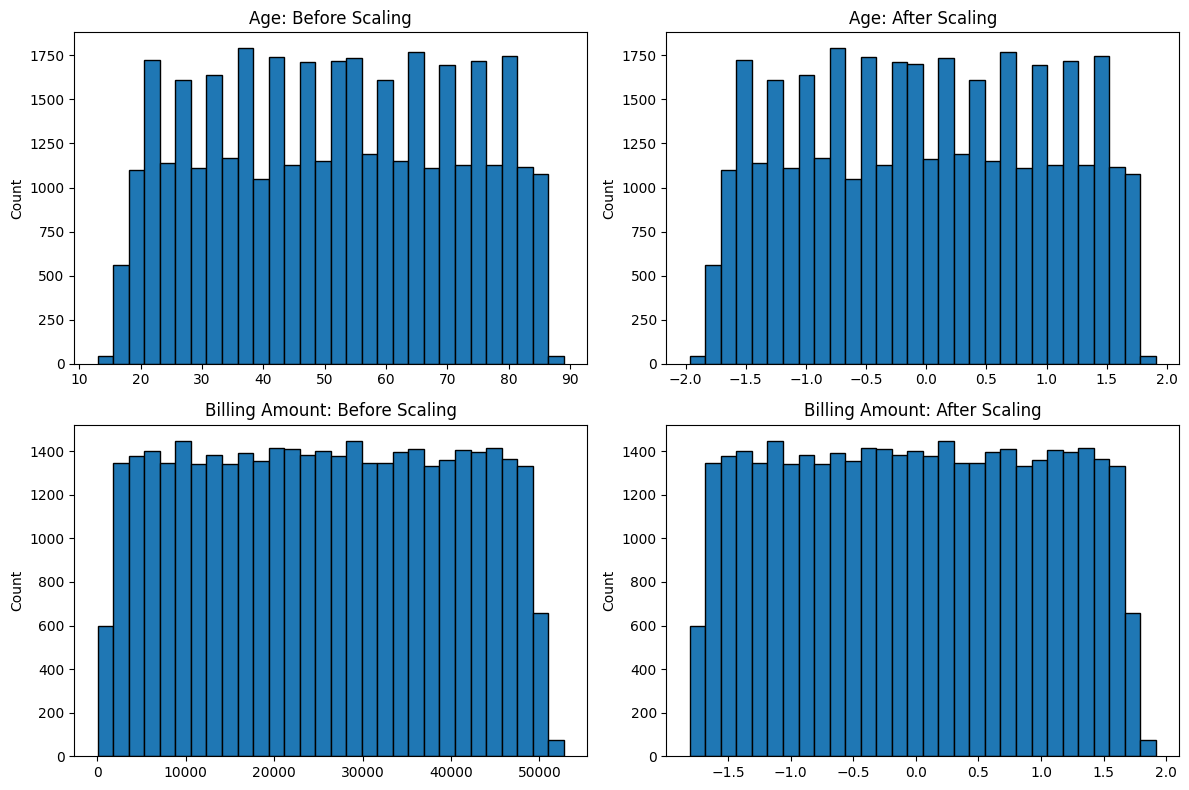

In [ ]:
# Scale numerical features using training data only
numeric_columns = ["Age", "Billing Amount"]

df_scaled = df_encoded.copy()
scaler = StandardScaler()

df_scaled[numeric_columns] = scaler.fit_transform(
    df_encoded[numeric_columns]
)

print("Before scaling:")
display(df_encoded[numeric_columns].head())

print("\nAfter scaling:")
display(df_scaled[numeric_columns].head())

print("\nScaled feature statistics:")
display(df_scaled[numeric_columns].agg(["mean", "std"]))

# Compare distributions before and after scaling
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for row, column in enumerate(numeric_columns):
    axes[row, 0].hist(
        df_encoded[column], bins=30, edgecolor="black"
    )
    axes[row, 0].set_title(f"{column}: Before Scaling")
    axes[row, 0].set_ylabel("Count")

    axes[row, 1].hist(
        df_scaled[column], bins=30, edgecolor="black"
    )
    axes[row, 1].set_title(f"{column}: After Scaling")
    axes[row, 1].set_ylabel("Count")

fig.tight_layout()
plt.show()

In [ ]:
# Include the encoded target in the final dataset
train_scaled = df_scaled.copy()
train_scaled["Test Results"] = y_train

# Export the preprocessed training dataset
train_scaled.to_csv("healthcare_train_processed.csv", index=False)

print("Preprocessed training dataset saved successfully!")
print("Final Dataset Shape:", train_scaled.shape)
display(train_scaled.head())

# Check missing values in the final training dataset
print("Final missing values:", train_scaled.isna().sum().sum())

# Save the testing dataset without preprocessing
test_df.to_csv("healthcare_test_untouched.csv", index=False)
print("Untouched testing dataset saved!")

Preprocessed training dataset saved successfully!
Final Dataset Shape: (38599, 31)


,Age,Billing Amount,Medication_Aspirin,Medication_Ibuprofen,Medication_Lipitor,Medication_Paracetamol,Medication_Penicillin,Medical Condition_Arthritis,Medical Condition_Asthma,Medical Condition_Cancer,...,Gender_Female,Gender_Male,Admission Type_Elective,Admission Type_Emergency,Admission Type_Urgent,Age_Group_Under 18,Age_Group_18-39,Age_Group_40-59,Age_Group_60+,Test Results
39555,-1.608636,-0.311072,0,1,0,0,0,0,0,0,...,1,0,1,0,0,0,1,0,0,2
25382,-0.589303,-1.310541,0,0,0,0,1,1,0,0,...,1,0,0,0,1,0,0,1,0,2
41604,-1.608636,0.852685,1,0,0,0,0,0,0,0,...,1,0,0,0,1,0,1,0,0,2
51069,1.500329,0.978471,0,1,0,0,0,0,0,0,...,0,1,0,0,1,0,0,0,1,1
45759,0.022296,-0.457490,1,0,0,0,0,1,0,0,...,0,1,1,0,0,0,0,1,0,1


Final missing values: 0
Untouched testing dataset saved!


### Conclusion and Future Machine Learning Use

The dataset was divided through Python into 70% training and 30%
testing before exploratory analysis and preprocessing. Cleanup
removed 251 duplicate training rows and replaced 78 negative billing
amounts with the training median under the assumption that billing
amounts should be non-negative.

Feature engineering, categorical encoding, and numerical scaling
produced a training dataset containing 38,599 rows and 31 columns,
including the target, with no missing values. Distribution
transformation and class balance were evaluated. The transformation
was not retained, and class resampling was unnecessary. All changes
were performed through code without manually editing the original CSV.

The data, supports a future multiclass classifications, to predict Test Results as Abnormal, Inconclusive, or Normal.
Logistic Regression and Decision Tree models can be compared using
accuracy, macro F1-score, and confusion matrices against a baseline.
Feature availability at prediction time must be checked, particularly
for medication and billing information.

Model selection will use cross-validation on training data, with
preprocessing fitted within each fold.